# Representar es elegir: cuándo se parecen dos textos

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

| | |
|---|---|
| **Problema** | Dos fragmentos que una persona acerca pueden quedar lejos para un contador de palabras. |
| **Producto** | Una función que mide la cercanía de un par, una que arma perfiles de contexto y una decisión de uso. |
| **Recursos** | Poca memoria; no descarga nada. Corre en segundos. |

Un sitio con cientos de cuentos quiere sugerir, al terminar uno, «otros parecidos». Para que una máquina lo haga, cada texto se convierte en números y se mide qué tan cerca quedan. Pero *parecido* puede querer decir que tratan el mismo tema, que cuentan una escena equivalente o que son del mismo género. Una persona distingue los tres sin esfuerzo; un número, no.

**¿Por qué dos fragmentos que una persona acerca pueden quedar lejos para un contador de palabras, y qué hay que cambiar?**

> **Cómo se trabaja.** Explorás cada tema con el código ya escrito y las notas **Para mirar**. Al final de cada bloque, un **microlaboratorio** te dice qué líneas completar y con qué; la celda siguiente comprueba.

In [1]:
import sys
import importlib.metadata

import numpy as np
import pandas as pd
from IPython.display import display

from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

import utils

# La semilla fija el unico paso con azar: la descomposicion SVD del final.
SEMILLA = 42
pd.set_option("display.max_colwidth", 120)

print("Python:", sys.version.split()[0])
for paquete in ["numpy", "pandas", "scikit-learn"]:
    print(f"{paquete}: {importlib.metadata.version(paquete)}")
print("Semilla:", SEMILLA)

Python: 3.12.13
numpy: 2.5.4
pandas: 3.0.6
scikit-learn: 1.9.1
Semilla: 42


## 1. Los textos y un criterio humano

| Campo | Contenido |
|---|---|
| Fuente | `cuentos_latinoamericanos.csv` (Karen Palacio, a partir de ciudadseva.com). Detalle en `datos/FUENTE.md` |
| Selección | 34 textos de 12 autores, elegidos por nosotros; no es una muestra al azar |
| Unidad | un **fragmento**: oraciones consecutivas que suman al menos 45 palabras (el corte es criterio nuestro) |
| Tamaño | 137 fragmentos. Los 12 autores son varones; abundan el humor, la ironía y la alegoría |
| Licencia | los derechos son de sus autores; son extractos breves con fin didáctico. La licencia de redistribución del compilado **no está verificada** |

Los números de este cuaderno describen esta colección, no el español en general.

In [2]:
fragmentos = utils.cargar_fragmentos()

assert fragmentos["id"].is_unique, "Hay ids repetidos."
assert fragmentos["texto"].str.len().min() > 0, "Hay fragmentos sin texto."
print(f"{len(fragmentos)} fragmentos de {fragmentos['titulo'].nunique()} "
      "textos. Ids unicos y textos completos.")

# Cinco pares y nuestro criterio de lectura, anotado antes de calcular.
# Es discutible: sirve de punto de comparacion, no de verdad.
pares = [
    {"etiqueta": "P1", "primero": "tres-cocineros-y-un-huevo-frito-01",
     "segundo": "la-cocinera-01",
     "criterio": "cercanos por tema (cocina)"},
    {"etiqueta": "P2", "primero": "el-suicida-01",
     "segundo": "suicidio-2-01",
     "criterio": "cercanos por tema (suicidio)"},
    {"etiqueta": "P3", "primero": "la-muerte-anderson-04",
     "segundo": "la-foto-02",
     "criterio": "NO cercanos: comparten 'muerte' pero no su papel"},
    {"etiqueta": "P4", "primero": "la-mosca-que-sonaba-que-era-un-aguila-01",
     "segundo": "la-rana-que-queria-ser-una-rana-autentica-01",
     "criterio": "cercanos por escena (un animal que quiere ser otro)"},
    {"etiqueta": "P5", "primero": "instrucciones-para-llorar-01",
     "segundo": "instrucciones-para-subir-una-escalera-01",
     "criterio": "cercanos por genero (instrucciones)"},
]
textos_por_id = fragmentos.set_index("id")["texto"].to_dict()
for par in pares:
    assert par["primero"] in textos_por_id, f"Falta {par['primero']}."
    assert par["segundo"] in textos_por_id, f"Falta {par['segundo']}."
    print(par["etiqueta"], "-", par["criterio"])
    print("   A:", textos_por_id[par["primero"]][:110], "...")
    print("   B:", textos_por_id[par["segundo"]][:110], "...")

137 fragmentos de 34 textos. Ids unicos y textos completos.
P1 - cercanos por tema (cocina)
   A: Hay tres cocineros en un hotel; el primero llama al segundo y le dice: “Atiéndeme ese huevo frito; debe ser as ...
   B: Por inaudito que parezca hubo cierta vez una cocinera excelente. La familia a quien servía se transportaba, a  ...
P2 - cercanos por tema (suicidio)
   A: Al pie de la Biblia abierta -donde estaba señalado en rojo el versículo que lo explicaría todo- alineó las car ...
   B: —Hay muchos modos de suicidarse. El que yo propongo es el siguiente: suicídese usted mediante el único método  ...
P3 - NO cercanos: comparten 'muerte' pero no su papel
   A: Soy la Muerte, la M-u-e-r-t-e. La automovilista sonrió misteriosamente. En la próxima curva el auto se desbarr ...
   B: ¡Clic! Poco después, la muerte. Entonces Jaime hizo ampliar la foto -la cara de Paula era bella como una flor- ...
P4 - cercanos por escena (un animal que quiere ser otro)
   A: Había una vez una Mosca que tod

> **Para mirar.** tres criterios aparecen seguido cuando decimos que dos textos «se parecen»: el mismo **tema** (P1, P2), la misma **escena** (P4) y el mismo **género** (P5). P3 es una trampa: comparte una palabra, no el papel que cumple.

## 2. Contar las palabras que comparten

La **bolsa de palabras** representa cada texto por cuántas veces usa cada palabra, sin orden. Dos textos se parecen si usan las mismas palabras, y se mide con el **coseno**: el ángulo entre los dos vectores. Con conteos va de 0 a 1; **0** significa «ninguna palabra en común», no «opuestos», y **1** significa «misma dirección», no «textos iguales».

Primero, el mecanismo con dos oraciones.

In [3]:
oraciones_de_prueba = [
    "la rana quería ser águila",
    "la mosca soñaba ser águila",
]

vectorizador_de_prueba = CountVectorizer(
    token_pattern=utils.PATRON_DE_PALABRA
)
conteos_de_prueba = vectorizador_de_prueba.fit_transform(
    raw_documents=oraciones_de_prueba
).toarray()

# Una columna por palabra distinta; una fila por oracion.
columnas = vectorizador_de_prueba.get_feature_names_out()
display(pd.DataFrame(conteos_de_prueba, columns=columnas))

# El coseno es el producto de las filas dividido por el largo de cada una.
producto = np.dot(conteos_de_prueba[0], conteos_de_prueba[1])
largos = (np.linalg.norm(conteos_de_prueba[0])
          * np.linalg.norm(conteos_de_prueba[1]))
coseno_a_mano = producto / largos
de_utils = utils.coseno(conteos_de_prueba[0], conteos_de_prueba[1])
assert abs(coseno_a_mano - de_utils) < 1e-9, "Los cosenos no coinciden."
print(f"Coseno: {coseno_a_mano:.3f}")

,la,mosca,quería,rana,ser,soñaba,águila
0,1,0,1,1,1,0,1
1,1,1,0,0,1,1,1


Coseno: 0.600


> **Para mirar.** comparten *la*, *ser* y *águila*: 3 de 5 palabras, coseno 0,6. Mirá que *la* pesa tanto como *águila*, aunque no dice nada de lo que cuentan. **TF-IDF** corrige eso dando más peso a las palabras que aparecen en pocos fragmentos. Y se pueden sacar las **palabras vacías** (*el*, *que*, *a*…), que es una decisión, no una limpieza neutral.

260 palabras vacias. Primeras: ['a', 'al', 'algo', 'algunas', 'algunos']
Conteos: (137, 2760) | TF-IDF: (137, 2760) | sin vacias: (137, 2641)


,conteo,TF-IDF,TF-IDF sin vacias
par,,,
P1,0.315,0.064,0.000
P2,0.339,0.046,0.000
P3,0.504,0.098,0.024
P4,0.460,0.123,0.018
P5,0.518,0.123,0.046


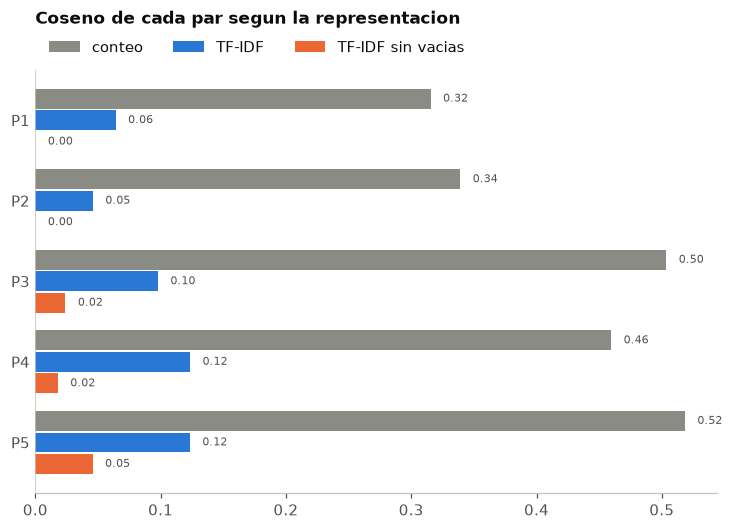

In [4]:
with open("datos/stopwords_es.txt", encoding="utf-8") as archivo:
    palabras_vacias = archivo.read().split()
print(f"{len(palabras_vacias)} palabras vacias. Primeras:",
      palabras_vacias[:5])

lista_de_ids = list(fragmentos["id"])
textos_de_la_coleccion = list(fragmentos["texto"])
patron = utils.PATRON_DE_PALABRA

conteos = CountVectorizer(token_pattern=patron).fit_transform(
    textos_de_la_coleccion
)
pesos_tfidf = TfidfVectorizer(token_pattern=patron).fit_transform(
    textos_de_la_coleccion
)
vectorizador_sin_vacias = TfidfVectorizer(
    token_pattern=patron, stop_words=palabras_vacias
)
pesos_sin_vacias = vectorizador_sin_vacias.fit_transform(
    textos_de_la_coleccion
)
print("Conteos:", conteos.shape, "| TF-IDF:", pesos_tfidf.shape,
      "| sin vacias:", pesos_sin_vacias.shape)

# Una fila por par y una columna por representacion.
matrices = {
    "conteo": conteos.toarray(),
    "TF-IDF": pesos_tfidf.toarray(),
    "TF-IDF sin vacias": pesos_sin_vacias.toarray(),
}
filas = []
for par in pares:
    fila = {"par": par["etiqueta"]}
    lugar_1 = lista_de_ids.index(par["primero"])
    lugar_2 = lista_de_ids.index(par["segundo"])
    for nombre, matriz in matrices.items():
        fila[nombre] = utils.coseno(matriz[lugar_1], matriz[lugar_2])
    filas.append(fila)
tabla_1 = pd.DataFrame(filas).set_index("par")
display(tabla_1.round(3))

series = {}
for nombre in tabla_1.columns:
    series[nombre] = list(tabla_1[nombre])
utils.dibujar_barras_agrupadas(
    list(tabla_1.index), series, "Coseno de cada par segun la representacion",
    colores={"conteo": utils.GRIS, "TF-IDF": utils.AZUL,
             "TF-IDF sin vacias": utils.NARANJA},
)

> **Para mirar.**
>
> - es lo contrario de lo esperado: sin palabras vacías, **P1 y P2 dan exactamente 0** (cocina y suicidio no comparten ninguna palabra con peso), mientras que P3, P4 y P5 dan un valor chico pero distinto de 0.
> - los conteos miden coincidencia de **formas escritas**. Sin palabras vacías, la semejanza depende de que se repita la misma palabra.

TF-IDF es una multiplicación de pesos palabra por palabra, así que se puede **abrir** el coseno y ver qué palabras lo explican.

In [5]:
def palabras_que_aportan(
    matriz_tfidf: csr_matrix, vectorizador: TfidfVectorizer,
    id_primero: str, id_segundo: str, cantidad: int = 5
) -> list:
    """Lista las palabras compartidas que mas aportan al coseno.

    El aporte de una palabra es su peso en un fragmento por su peso en el
    otro. Si falta en alguno, aporta 0.

    Args:
        matriz_tfidf: Matriz TF-IDF de la coleccion (una fila por fragmento).
        vectorizador: El vectorizador que la genero.
        id_primero: Id del primer fragmento.
        id_segundo: Id del segundo fragmento.
        cantidad: Cuantas palabras mostrar.

    Returns:
        Lista de tuplas (palabra, aporte), de mayor a menor aporte.
    """
    matriz = matriz_tfidf.toarray()
    fila_1 = matriz[lista_de_ids.index(id_primero)]
    fila_2 = matriz[lista_de_ids.index(id_segundo)]
    aportes = fila_1 * fila_2
    nombres = vectorizador.get_feature_names_out()
    resultado = []
    for posicion in np.argsort(-aportes)[:cantidad]:
        if aportes[posicion] > 0:
            resultado.append((nombres[posicion],
                              round(float(aportes[posicion]), 3)))
    return resultado


for par in pares:
    if par["etiqueta"] in ["P3", "P4"]:
        print(par["etiqueta"], "sin vacias:", palabras_que_aportan(
            pesos_sin_vacias, vectorizador_sin_vacias,
            par["primero"], par["segundo"]
        ))

P3 sin vacias: [('muerte', 0.024)]
P4 sin vacias: [('vez', 0.009), ('había', 0.008)]


> **Para mirar.**
>
> - **P3** es una coincidencia engañosa: *muerte* es un personaje en un fragmento y un hecho en el otro, pero la representación solo ve la misma cadena de letras.
> - **P4** es el caso contrario: dos fábulas de un animal que quiere ser otro, y lo único que comparten es *vez* y *había*, la fórmula «había una vez», una convención de apertura, no el tema.
> - **P2** habla del mismo tema con palabras de la misma familia (*suicida*, *suicidio*, *suicidarse*) que no coinciden en su forma. Agruparlas (lematizar, como hace spaCy) ayudaría, pero no resolvería *veneno*, que no comparte raíz con ninguna.

## 3. Decisiones que cambian qué es «igual»

Cómo se corta el texto también es una decisión. Los **bigramas** (pares de palabras consecutivas tratados como una unidad) piden coincidencia de dos palabras seguidas. `ngram_range=(1, 2)` pide unigramas y bigramas juntos.

Vocabulario unigramas: 2760
Vocabulario unigramas + bigramas: 9188


,TF-IDF,con bigramas,sin vacias,bigramas sin vacias
par,,,,
P1,0.064,0.026,0.000,0.000
P2,0.046,0.017,0.000,0.000
P3,0.098,0.054,0.024,0.011
P4,0.123,0.072,0.018,0.020
P5,0.123,0.049,0.046,0.023


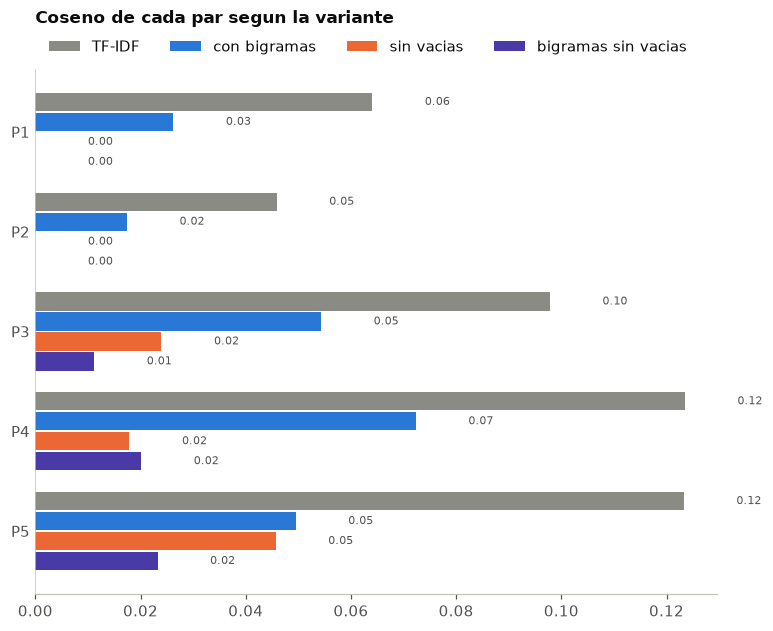

In [6]:
con_bigramas = TfidfVectorizer(token_pattern=patron, ngram_range=(1, 2))
pesos_con_bigramas = con_bigramas.fit_transform(textos_de_la_coleccion)
bigramas_sin_vacias = TfidfVectorizer(
    token_pattern=patron, ngram_range=(1, 2), stop_words=palabras_vacias
)
pesos_bigramas_sin_vacias = bigramas_sin_vacias.fit_transform(
    textos_de_la_coleccion
)
print("Vocabulario unigramas:", pesos_tfidf.shape[1])
print("Vocabulario unigramas + bigramas:", pesos_con_bigramas.shape[1])

matrices_2 = {
    "TF-IDF": matrices["TF-IDF"],
    "con bigramas": pesos_con_bigramas.toarray(),
    "sin vacias": matrices["TF-IDF sin vacias"],
    "bigramas sin vacias": pesos_bigramas_sin_vacias.toarray(),
}
filas = []
for par in pares:
    fila = {"par": par["etiqueta"]}
    lugar_1 = lista_de_ids.index(par["primero"])
    lugar_2 = lista_de_ids.index(par["segundo"])
    for nombre, matriz in matrices_2.items():
        fila[nombre] = utils.coseno(matriz[lugar_1], matriz[lugar_2])
    filas.append(fila)
tabla_2 = pd.DataFrame(filas).set_index("par")
display(tabla_2.round(3))

series = {}
for nombre in tabla_2.columns:
    series[nombre] = list(tabla_2[nombre])
utils.dibujar_barras_agrupadas(
    list(tabla_2.index), series, "Coseno de cada par segun la variante",
    colores={"TF-IDF": utils.GRIS, "con bigramas": utils.AZUL,
             "sin vacias": utils.NARANJA,
             "bigramas sin vacias": utils.VIOLETA},
)

> **Para mirar.**
>
> - los bigramas multiplican el vocabulario (de 2.760 a 9.188) y, en casi todos los pares, **bajan** los valores: exigir dos palabras seguidas vuelve más estricto lo que cuenta como «igual». Ayuda para buscar expresiones fijas y perjudica para buscar un tema.
> - ninguna columna es la correcta: responden preguntas distintas (¿comparten palabras?, ¿palabras raras?, ¿secuencias?). Y ninguna usa información sobre el sentido: *cocinero* y *cocinera* son columnas sin relación.

### Microlaboratorio 1 — Medir la cercanía de un par

**Tarea.** Escribir la función que mide la cercanía de dos fragmentos con cualquier representación y usarla con un par propio.  
**Producto.** `cercania_de_un_par`, comprobada, y la tabla de tu par con las cuatro variantes.  
**Antes de empezar.** Secciones 2 y 3.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `lugar_1` | la posición del primer fragmento | el método `.index` de la lista `lista_de_ids`, con `id_primero` |
| (2) `lugar_2` | la posición del segundo fragmento | lo mismo, con `id_segundo` |
| (3) `coseno` | el coseno entre las dos filas | `utils.coseno` con `matriz[lugar_1]` y `matriz[lugar_2]` |
| Paso 2 `mi_primero`, `mi_segundo` | dos ids de fragmentos | ids de la columna `id` de `fragmentos` (por ejemplo, de P1 a P5) |

**Comprobación.** `cercania_de_un_par` tiene que dar 0,315 para P1 con conteo y 0,018 para P4 con TF-IDF sin palabras vacías.

> **Ayuda 1.** Es lo que hace el bucle de la tabla de la sección 2, escrito como función.  
> **Ayuda 2.** Los ids son textos como `"la-cocinera-01"`; `.index` devuelve en qué lugar de la lista están.

In [7]:
def cercania_de_un_par(
    matriz: np.ndarray, id_primero: str, id_segundo: str
) -> float:
    """Calcula el coseno entre dos fragmentos de la coleccion.

    Args:
        matriz: Matriz con una fila por fragmento, en el orden de
            lista_de_ids.
        id_primero: Id del primer fragmento.
        id_segundo: Id del segundo fragmento.

    Returns:
        El coseno entre las dos filas.
    """
    lugar_1 = 0  # COMPLETAR (1)
    lugar_2 = 0  # COMPLETAR (2)
    coseno = 0.0  # COMPLETAR (3)
    return coseno


p1 = pares[0]
p4 = pares[3]
utils.comprobar(
    abs(cercania_de_un_par(matrices["conteo"], p1["primero"], p1["segundo"])
        - 0.315) < 0.001
    and abs(cercania_de_un_par(matrices["TF-IDF sin vacias"],
                               p4["primero"], p4["segundo"]) - 0.018) < 0.001,
    "revisa (1), (2) y (3): P1 con conteo = 0.315; P4 sin vacias = 0.018",
)

# PASO 2: cambia estos dos ids por los de tu par.
mi_primero = "tres-cocineros-y-un-huevo-frito-01"
mi_segundo = "la-cocinera-01"
assert mi_primero in lista_de_ids, "El primer id no esta en la coleccion."
assert mi_segundo in lista_de_ids, "El segundo id no esta en la coleccion."
for nombre, matriz in matrices_2.items():
    valor = cercania_de_un_par(matriz, mi_primero, mi_segundo)
    print(f"{nombre}: {valor:.3f}")

Todavia falta. Pista: revisa (1), (2) y (3): P1 con conteo = 0.315; P4 sin vacias = 0.018
TF-IDF: 0.000
con bigramas: 0.000
sin vacias: 0.000
bigramas sin vacias: 0.000


**Para pensar:** ¿qué criterio humano (tema, escena, género) estás usando para tu par? ¿Qué columna lo respeta menos y por qué?

## 4. Donde contar no alcanza: compartir contexto

Ninguna de esas representaciones acerca *papá* y *padre* si no aparecen en el mismo texto. Una salida es describir cada palabra por **los vecinos con los que aparece** (su *perfil de contexto*): si *papá* y *padre* aparecen con *abrazó*, *hija* e *hijo*, sus perfiles se parecen aunque jamás compartan una oración. Es la idea que sustenta a Word2Vec.

Para ver el mecanismo sin ruido usamos un **microcorpus construido por nosotros**: 14 oraciones de tres campos (familia, fútbol, escritura). No es evidencia sobre el español ni sobre ninguna colección real.

14 oraciones y 30 palabras distintas.
Matriz de coocurrencias: (30, 30)


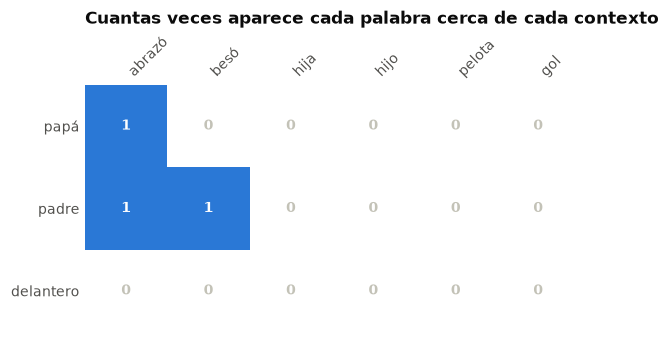

In [8]:
# Datos construidos: no provienen de ningun texto real.
oraciones_construidas = [
    "papá abrazó a su hija", "papá cocinó para su hijo",
    "padre abrazó a su hija", "padre besó a su hijo",
    "mamá besó a su hijo", "madre besó a su hija",
    "el delantero pateó la pelota", "el arquero atajó la pelota",
    "el delantero gritó el gol", "el arquero atajó el penal",
    "el poeta escribió un poema", "el novelista escribió una novela",
    "el poeta leyó el poema", "el novelista leyó la novela",
]

vocabulario = []
for oracion in oraciones_construidas:
    for palabra in oracion.split():
        if palabra not in vocabulario:
            vocabulario.append(palabra)
vocabulario = sorted(vocabulario)
print(f"{len(oraciones_construidas)} oraciones y {len(vocabulario)} "
      "palabras distintas.")

# Para cada palabra (el centro) contamos cuantas veces aparece cada otra
# dentro de una ventana de VENTANA palabras a cada lado.
VENTANA = 2

coocurrencias = pd.DataFrame(0, index=vocabulario, columns=vocabulario)
for oracion in oraciones_construidas:
    palabras = oracion.split()
    lugar = 0
    for centro in palabras:
        desde = max(0, lugar - VENTANA)
        hasta = min(len(palabras), lugar + VENTANA + 1)
        for lugar_del_contexto in range(desde, hasta):
            if lugar_del_contexto != lugar:
                contexto = palabras[lugar_del_contexto]
                coocurrencias.loc[centro, contexto] += 1
        lugar += 1

print("Matriz de coocurrencias:", coocurrencias.shape)
palabras_a_mostrar = ["papá", "padre", "delantero"]
contextos_a_mostrar = ["abrazó", "besó", "hija", "hijo", "pelota", "gol"]
recorte = coocurrencias.loc[palabras_a_mostrar, contextos_a_mostrar]
utils.dibujar_mapa_de_calor(
    recorte, palabras_a_mostrar, contextos_a_mostrar,
    "Cuantas veces aparece cada palabra cerca de cada contexto",
)

In [9]:
def parecido_de_perfiles(
    matriz: pd.DataFrame, palabra_a: str, palabra_b: str
) -> float:
    """Calcula el coseno entre los perfiles de contexto de dos palabras.

    Args:
        matriz: Tabla con una fila por palabra.
        palabra_a: Primera palabra.
        palabra_b: Segunda palabra.

    Returns:
        El coseno, redondeado a dos decimales.
    """
    return round(utils.coseno(matriz.loc[palabra_a].values,
                              matriz.loc[palabra_b].values), 2)


pares_de_palabras = [
    ("papá", "padre"), ("papá", "mamá"), ("papá", "delantero"),
    ("poeta", "novelista"), ("delantero", "arquero"),
]
for palabra_a, palabra_b in pares_de_palabras:
    valor = parecido_de_perfiles(coocurrencias, palabra_a, palabra_b)
    print(f"{palabra_a} ~ {palabra_b}: {valor}")

papá ~ padre: 0.61
papá ~ mamá: 0.35
papá ~ delantero: 0.0
poeta ~ novelista: 0.82
delantero ~ arquero: 0.77


> **Para mirar.**
>
> - *papá* y *padre* tienen perfiles parecidos (0,61) y *papá* con *delantero* queda en 0, aunque *papá* y *padre* nunca aparecen juntos. La semejanza surge de **compartir vecinos**, no de co-aparecer.
> - pero son 14 oraciones diseñadas para que pase. En un corpus real, las palabras frecuentes aparecen cerca de todo y dominan los perfiles.

**PPMI** corrige eso: en vez del conteo crudo, mide si dos palabras aparecen juntas **más de lo que esperaríamos por azar** (los valores negativos se llevan a 0). Después, la **SVD** comprime la matriz a pocas columnas: son vectores *densos*, pocos números por palabra.

In [10]:
total = coocurrencias.values.sum()
probabilidad_conjunta = coocurrencias.values / total
probabilidad_de_cada_palabra = probabilidad_conjunta.sum(axis=1)

# Lo que esperariamos si las palabras se acomodaran al azar.
esperado_por_azar = np.outer(
    probabilidad_de_cada_palabra, probabilidad_de_cada_palabra
)
# Donde no hay coocurrencia el logaritmo da -inf: pasa a 0 con el maximo.
with np.errstate(divide="ignore"):
    asociacion = np.log2(probabilidad_conjunta / esperado_por_azar)
ppmi = pd.DataFrame(
    np.maximum(asociacion, 0), index=vocabulario, columns=vocabulario
)

CANTIDAD_DE_DIMENSIONES = 4
descomposicion = TruncatedSVD(
    n_components=CANTIDAD_DE_DIMENSIONES, random_state=SEMILLA
)
vectores_densos = pd.DataFrame(
    descomposicion.fit_transform(X=ppmi.values), index=vocabulario
)
varianza = descomposicion.explained_variance_ratio_.sum()
print(f"SVD en {CANTIDAD_DE_DIMENSIONES} dimensiones: "
      f"{varianza:.0%} de la varianza.")

for palabra_a, palabra_b in pares_de_palabras:
    en_ppmi = parecido_de_perfiles(ppmi, palabra_a, palabra_b)
    en_denso = parecido_de_perfiles(vectores_densos, palabra_a, palabra_b)
    print(f"{palabra_a} ~ {palabra_b}: PPMI {en_ppmi} | denso {en_denso}")

SVD en 4 dimensiones: 37% de la varianza.
papá ~ padre: PPMI 0.42 | denso 1.0
papá ~ mamá: PPMI 0.11 | denso 1.0
papá ~ delantero: PPMI 0.0 | denso 0.0
poeta ~ novelista: PPMI 0.44 | denso 0.97
delantero ~ arquero: PPMI 0.36 | denso 1.0


> **Para mirar.**
>
> - con PPMI los valores bajan (*papá ~ padre* de 0,61 a 0,42): el conteo crudo premia vecinos que aparecen con casi todo (*su*, *a*, *el*). Bajar el valor no lo vuelve más «verdadero»: cambia el criterio.
> - con 4 dimensiones, *papá ~ mamá* y *delantero ~ arquero* dan 1,0: la compresión separa los campos pero **borra las diferencias dentro de cada uno**. Comprimir es decidir qué se conserva. La varianza explicada (37 %) mide variación numérica, no cuánto significado queda.

### Microlaboratorio 2 — Perfiles de contexto con otra ventana

**Tarea.** Convertir el bucle de coocurrencias en una función y ver qué hace la ventana con el parecido entre *papá* y *mamá*.  
**Producto.** `construir_coocurrencias`, comprobada, y los parecidos para tres ventanas.  
**Antes de empezar.** Sección 4.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `desde` | primera posición de la ventana | el mayor entre `0` y `lugar - ventana` (función `max`) |
| (2) `hasta` | posición siguiente a la última | el menor entre `len(palabras)` y `lugar + ventana + 1` (función `min`) |
| (3) `tabla.loc[centro, contexto]` | sumar 1 al conteo | el operador `+= 1` sobre esa celda |

**Comprobación.** la suma total de la matriz tiene que dar 112, 196 y 280 con ventanas 1, 2 y 4.

> **Ayuda 1.** Es el mismo bucle de la sección 4. Las líneas (1) y (2) evitan que la ventana se salga de la oración.  
> **Ayuda 2.** La línea (3) es la que va dentro del `if`, igual que en la sección 4.

In [11]:
def construir_coocurrencias(
    oraciones: list, vocabulario: list, ventana: int
) -> pd.DataFrame:
    """Cuenta cuantas veces aparece cada palabra cerca de otra.

    Args:
        oraciones: Lista de oraciones (textos).
        vocabulario: Palabras distintas, ordenadas.
        ventana: Cuantas palabras a cada lado cuentan como contexto.

    Returns:
        Tabla con una fila y una columna por palabra del vocabulario.
    """
    tabla = pd.DataFrame(0, index=vocabulario, columns=vocabulario)
    for oracion in oraciones:
        palabras = oracion.split()
        lugar = 0
        for centro in palabras:
            desde = 0  # COMPLETAR (1)
            hasta = 0  # COMPLETAR (2)
            for lugar_del_contexto in range(desde, hasta):
                if lugar_del_contexto != lugar:
                    contexto = palabras[lugar_del_contexto]
                    pass  # COMPLETAR (3)
            lugar += 1
    return tabla


totales = []
for ventana_de_prueba in [1, 2, 4]:
    tabla_de_prueba = construir_coocurrencias(
        oraciones_construidas, vocabulario, ventana_de_prueba
    )
    totales.append(int(tabla_de_prueba.values.sum()))
utils.comprobar(
    totales == [112, 196, 280],
    f"revisa (1), (2) y (3): se esperaba [112, 196, 280] y salio {totales}",
)

# PASO 2: mira como cambia el parecido con la ventana.
for ventana_de_prueba in [1, 2, 4]:
    tabla_de_prueba = construir_coocurrencias(
        oraciones_construidas, vocabulario, ventana_de_prueba
    )
    padre = parecido_de_perfiles(tabla_de_prueba, "papá", "padre")
    mama = parecido_de_perfiles(tabla_de_prueba, "papá", "mamá")
    print(f"ventana {ventana_de_prueba}: papa~padre {padre} | "
          f"papa~mama {mama}")

Todavia falta. Pista: revisa (1), (2) y (3): se esperaba [112, 196, 280] y salio [0, 0, 0]
ventana 1: papa~padre nan | papa~mama nan
ventana 2: papa~padre nan | papa~mama nan
ventana 4: papa~padre nan | papa~mama nan


**Para pensar:** con ventana 1, *papá ~ mamá* da 0; con ventana 4, sube a 0,63. La ventana decide qué cuenta como «cerca» y, con ella, qué se parece a qué.

## 5. Decidir qué representación sirve para qué

| Representación | Dos textos se parecen si… | No distingue ni ve |
|---|---|---|
| Conteo de palabras | usan las mismas palabras | tema, orden, sentido |
| TF-IDF | comparten palabras raras de la colección | sinónimos, formas de una palabra, orden |
| N-gramas | repiten secuencias de palabras | variación léxica; ocupa mucho espacio |
| Perfil de contexto (PPMI) | sus palabras aparecen con vecinos parecidos | polisemia, orden, antónimos |
| Vectores densos (SVD) | lo mismo, comprimido | qué significa cada dimensión; cuánto sentido se perdió |

- **Buscar frases hechas** en un corpus: bigramas.
- **Encontrar fragmentos que repiten una palabra clave**, o poder explicar por qué se parecen: bolsa de palabras y TF-IDF, que son transparentes (se puede abrir el número, como hicimos con `palabras_que_aportan`).
- **Agrupar por tema**: con nuestros cinco pares, ninguna representación de conteo alcanza (P1 y P2 dieron 0).

Los vectores densos cambian el criterio de semejanza; no lo vuelven más «inteligente» ni más objetivo. Y no hay un umbral universal de parecido: depende de la representación y de la colección.

## Qué te llevás

- Una representación **es una elección**: define qué cuenta como «igual» y qué diferencias desaparecen.
- Contar palabras ve formas escritas, no temas ni escenas; quitar palabras vacías y usar bigramas cambia qué es «igual».
- Los perfiles de contexto acercan palabras que **comparten vecinos**; comprimir conserva el campo y borra las diferencias dentro de él.

**Sigue:** cómo se aprende esa tabla de vectores en lugar de armarla a mano (cuaderno 02, Word2Vec).